Install Dependencies

In [3]:
!pip install -q transformers datasets tokenizers accelerate scikit-learn \
    matplotlib seaborn pandas tqdm onnxruntime

Imports & Configuration

In [4]:
import os, sys, json, re, csv, time, warnings, math
from pathlib import Path
from collections import Counter, defaultdict
from typing import List, Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from transformers import (
    AutoConfig, AutoTokenizer, AutoModel,
    AutoModelForMaskedLM, AutoModelForSequenceClassification,
    AutoModelForTokenClassification, pipeline
)
from sklearn.metrics import (
    classification_report, f1_score, accuracy_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ── Paths ──
DATA_DIR = Path("./data")
DATA_DIR.mkdir(exist_ok=True)
LID_DIR  = DATA_DIR / "L3Cube-HingLID"
LID_DIR.mkdir(exist_ok=True)
EVAL_DIR = DATA_DIR / "eval"
EVAL_DIR.mkdir(exist_ok=True)
FIG_DIR  = Path("./figures")
FIG_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


HingBERT Teacher — Architecture Inspection

In [5]:
print("=" * 70)
print("════ REPORT BACK: TEACHER INSPECTION ════")
print("=" * 70)

TEACHER_NAME = "l3cube-pune/hing-bert"

# Load config (no big download yet)
teacher_config = AutoConfig.from_pretrained(TEACHER_NAME)
print(f"\nModel name       : {TEACHER_NAME}")
print(f"Architecture     : {teacher_config.architectures}")
print(f"Hidden size      : {teacher_config.hidden_size}")
print(f"Num layers       : {teacher_config.num_hidden_layers}")
print(f"Num attn heads   : {teacher_config.num_attention_heads}")
print(f"Intermediate size: {teacher_config.intermediate_size}")
print(f"Vocab size       : {teacher_config.vocab_size}")
print(f"Max position emb : {teacher_config.max_position_embeddings}")
print(f"Model type       : {teacher_config.model_type}")

# Load full model to count params
teacher_tok = AutoTokenizer.from_pretrained(TEACHER_NAME)
teacher_model = AutoModelForMaskedLM.from_pretrained(TEACHER_NAME)
teacher_model.eval()

total_params = sum(p.numel() for p in teacher_model.parameters())
trainable_params = sum(p.numel() for p in teacher_model.parameters() if p.requires_grad)
embedding_params = sum(
    p.numel() for name, p in teacher_model.named_parameters()
    if "embedding" in name.lower()
)

print(f"\nTotal parameters : {total_params:,}")
print(f"Trainable params : {trainable_params:,}")
print(f"Embedding params : {embedding_params:,}")
print(f"Non-embed params : {total_params - embedding_params:,}")
print(f"Model size (MB)  : {total_params * 4 / 1024**2:.1f}  (FP32)")

# Proposed student: 6 layers → estimate
student_layers = 6
# Rough estimate: embedding + 6/12 of transformer blocks + pooler
est_student_params = embedding_params + (
    (total_params - embedding_params) * student_layers / teacher_config.num_hidden_layers
)
print(f"\nEstimated 6-layer student params: {est_student_params:,.0f}")
print(f"Compression ratio: {total_params / est_student_params:.2f}×")
print(f"Estimated student size (MB): {est_student_params * 4 / 1024**2:.1f}  (FP32)")

# Tokenizer info
print(f"\nTokenizer class  : {type(teacher_tok).__name__}")
print(f"Vocab size (tok) : {teacher_tok.vocab_size}")
print(f"Special tokens   : {teacher_tok.all_special_tokens}")

# Quick tokenization test on Hinglish text
test_sents = [
    "yaar ye movie bahut acchi thi",
    "I think this is really badiya plan hai",
    "kya hua bhai, why so serious",
]
print("\nTokenization examples:")
for s in test_sents:
    toks = teacher_tok.tokenize(s)
    print(f"  '{s}' → {toks}")

del teacher_model  # Free memory
torch.cuda.empty_cache() if torch.cuda.is_available() else None

════ REPORT BACK: TEACHER INSPECTION ════


config.json:   0%|          | 0.00/716 [00:00<?, ?B/s]


Model name       : l3cube-pune/hing-bert
Architecture     : ['BertForMaskedLM']
Hidden size      : 768
Num layers       : 12
Num attn heads   : 12
Intermediate size: 3072
Vocab size       : 30522
Max position emb : 512
Model type       : bert


tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Total parameters : 109,514,298
Trainable params : 109,514,298
Embedding params : 23,837,184
Non-embed params : 85,677,114
Model size (MB)  : 417.8  (FP32)

Estimated 6-layer student params: 66,675,741
Compression ratio: 1.64×
Estimated student size (MB): 254.3  (FP32)

Tokenizer class  : BertTokenizer
Vocab size (tok) : 30522
Special tokens   : ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']

Tokenization examples:
  'yaar ye movie bahut acchi thi' → ['ya', '##ar', 'ye', 'movie', 'ba', '##hu', '##t', 'acc', '##hi', 'th', '##i']
  'I think this is really badiya plan hai' → ['i', 'think', 'this', 'is', 'really', 'bad', '##iya', 'plan', 'hai']
  'kya hua bhai, why so serious' → ['ky', '##a', 'hua', 'b', '##hai', ',', 'why', 'so', 'serious']


Download L3Cube-HingLID Gold Data

In [6]:
import urllib.request

HINGLID_BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"

for split in ["train", "test", "validation"]:
    fpath = LID_DIR / f"{split}.txt"
    if not fpath.exists():
        url = f"{HINGLID_BASE}/{split}.txt"
        print(f"Downloading {url} ...")
        urllib.request.urlretrieve(url, str(fpath))
        print(f"  → saved to {fpath}  ({fpath.stat().st_size / 1024:.0f} KB)")
    else:
        print(f"Already exists: {fpath}  ({fpath.stat().st_size / 1024:.0f} KB)")


  → saved to data/L3Cube-HingLID/train.txt  (7600 KB)
  → saved to data/L3Cube-HingLID/test.txt  (1519 KB)
  → saved to data/L3Cube-HingLID/validation.txt  (1517 KB)


Parse & Inspect L3Cube-HingLID Data Format

In [7]:
def parse_hinglid_file(filepath: str) -> Tuple[list, str]:
    """
    Auto-detect format of HingLID data.
    Returns (parsed_data, format_type).

    Possible formats:
    - 'word_level': CoNLL-like, one token per line with lang tag, blank line = sentence boundary
    - 'sentence_level': one line = sentence with a label (tab-separated)
    """
    with open(filepath, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()

    # Peek at first 20 non-empty lines to detect format
    sample_lines = [l.strip() for l in lines[:50] if l.strip()]

    # Check if lines have exactly 2 tab/space-separated columns
    tab_cols = [len(l.split("\t")) for l in sample_lines[:20]]
    space_cols = [len(l.split()) for l in sample_lines[:20]]

    # Word-level: lines with 2 columns (word \t tag), blank lines as separators
    if all(c == 2 for c in tab_cols[:10]):
        return _parse_word_level(lines, sep="\t"), "word_level_tab"
    elif all(c == 2 for c in space_cols[:10]):
        return _parse_word_level(lines, sep=None), "word_level_space"
    elif all(c >= 3 for c in tab_cols[:10]):
        # Could be "sentence \t label" format or multi-column
        return _parse_sentence_level(lines, sep="\t"), "sentence_level"
    else:
        # Try word-level with mixed separators
        return _parse_word_level(lines, sep=None), "word_level_auto"


def _parse_word_level(lines, sep=None):
    """Parse CoNLL-like word-level LID data."""
    sentences = []
    current_tokens = []
    current_tags = []

    for line in lines:
        line = line.strip()
        if not line:
            if current_tokens:
                sentences.append({
                    "tokens": current_tokens,
                    "tags": current_tags,
                    "text": " ".join(current_tokens)
                })
                current_tokens = []
                current_tags = []
            continue

        parts = line.split(sep) if sep else line.split()
        if len(parts) >= 2:
            token = parts[0]
            tag = parts[-1]  # Last column is the tag
            current_tokens.append(token)
            current_tags.append(tag)
        elif len(parts) == 1:
            # Might be a sentence-level label on its own line
            current_tokens.append(parts[0])
            current_tags.append("UNK")

    # Don't forget the last sentence
    if current_tokens:
        sentences.append({
            "tokens": current_tokens,
            "tags": current_tags,
            "text": " ".join(current_tokens)
        })

    return sentences


def _parse_sentence_level(lines, sep="\t"):
    """Parse sentence-level LID data."""
    sentences = []
    for line in lines:
        line = line.strip()
        if not line:
            continue
        parts = line.split(sep)
        if len(parts) >= 2:
            sentences.append({
                "text": parts[0].strip(),
                "label": parts[-1].strip()
            })
    return sentences


# Parse all splits
lid_data = {}
for split in ["train", "test", "validation"]:
    fpath = LID_DIR / f"{split}.txt"
    data, fmt = parse_hinglid_file(str(fpath))
    lid_data[split] = data
    print(f"\n{split}: {len(data)} samples, format: {fmt}")

    # Show first 3 samples
    for i, sample in enumerate(data[:3]):
        print(f"  Sample {i}: {json.dumps(sample, ensure_ascii=False)[:200]}")

# Determine if word-level or sentence-level
sample = lid_data["train"][0]
is_word_level = "tags" in sample and "tokens" in sample
IS_WORD_LEVEL_LID = is_word_level

print(f"\n════ REPORT BACK: LID DATA FORMAT ════")
print(f"Format detected: {'WORD-LEVEL' if IS_WORD_LEVEL_LID else 'SENTENCE-LEVEL'}")
print(f"Train: {len(lid_data['train'])} sentences")
print(f"Test:  {len(lid_data['test'])} sentences")
print(f"Val:   {len(lid_data['validation'])} sentences")

if IS_WORD_LEVEL_LID:
    # Count tag distribution
    all_tags = []
    for sample in lid_data["train"]:
        all_tags.extend(sample["tags"])
    tag_counts = Counter(all_tags)
    print(f"\nTag distribution (train):")
    for tag, count in tag_counts.most_common():
        print(f"  {tag}: {count} ({count/len(all_tags)*100:.1f}%)")

    # Count total tokens
    total_tokens = sum(len(s["tokens"]) for s in lid_data["train"])
    print(f"Total tokens (train): {total_tokens:,}")
else:
    all_labels = [s["label"] for s in lid_data["train"]]
    label_counts = Counter(all_labels)
    print(f"\nLabel distribution (train):")
    for lbl, count in label_counts.most_common():
        print(f"  {lbl}: {count} ({count/len(all_labels)*100:.1f}%)")


train: 31756 samples, format: word_level_tab
  Sample 0: {"tokens": ["sanatan", "0809", "tiding", "luna", "in", "ham", "bowling", "krte", "hai", "aap", "apne", "stump", "bhjao"], "tags": ["HI", "HI", "EN", "EN", "EN", "HI", "EN", "HI", "HI", "HI", "HI", "EN
  Sample 1: {"tokens": ["aap", "ne", "kaha", "tha", "apne", "video", "main", "ki", "koi", "video", "share", "kare", "him", "toh", "yeh", "link", "hai", "aap", "aksar", "poochti", "hai", "maulana", "saab", "se", "
  Sample 2: {"tokens": ["gill", "main", "first", "time", "bb13", "ko", "apne", "friends", "ke", "yaha", "dekhi", "mujhe", "bigboss", "me", "koi", "intrest", "nahi", "tha", "but", "jaise", "hi", "shehnaaz", "ki", 

test: 6420 samples, format: word_level_tab
  Sample 0: {"tokens": ["hai", "behan", "ki", "l", "hai", "test", "karna", "ho", "ek", "baar", "isse", "boliyega", "modi", "ji", "hai", "to", "to", "mumkin", "hai", "fir", "ye", "apne", "asli", "rang", "par", "aa
  Sample 1: {"tokens": ["apne", "papa", "ki", "pic", "laga

Build Word-Level LID Tagger

In [8]:
# Strategy: Character n-gram Logistic Regression trained on HingLID gold data
# This is lightweight, fast, and validated directly on the gold test set.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# ── Standardize tags ──
# Common HingLID tags: 'hi' (Hindi), 'en' (English), 'rest'/'univ'/'other'
# We normalize to: HI, EN, OTHER

TAG_MAP = {
    "hi": "HI", "hin": "HI", "hindi": "HI",
    "en": "EN", "eng": "EN", "english": "EN",
    "rest": "OTHER", "univ": "OTHER", "other": "OTHER",
    "ne": "OTHER", "mixed": "OTHER", "fw": "OTHER",
    "acro": "OTHER", "undef": "OTHER", "unk": "OTHER",
}

def normalize_tag(tag: str) -> str:
    tag_lower = tag.lower().strip()
    return TAG_MAP.get(tag_lower, "OTHER")


if IS_WORD_LEVEL_LID:
    # Prepare training data for character n-gram classifier
    def prepare_lid_data(data_split):
        words = []
        labels = []
        for sample in data_split:
            for token, tag in zip(sample["tokens"], sample["tags"]):
                words.append(token.lower())
                labels.append(normalize_tag(tag))
        return words, labels

    train_words, train_labels = prepare_lid_data(lid_data["train"])
    test_words, test_labels = prepare_lid_data(lid_data["test"])
    val_words, val_labels = prepare_lid_data(lid_data["validation"])

    print(f"Training LID classifier on {len(train_words):,} tokens...")
    print(f"Tag distribution: {Counter(train_labels)}")

    # Character n-gram TF-IDF + Logistic Regression
    lid_classifier = Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(2, 5),
            max_features=100000,
            sublinear_tf=True
        )),
        ("clf", LogisticRegression(
            max_iter=1000,
            C=1.0,
            solver="lbfgs",
            multi_class="multinomial",
            n_jobs=-1
        ))
    ])

    lid_classifier.fit(train_words, train_labels)
    print("LID classifier trained.")

    # Quick sanity check
    test_tokens = ["hello", "world", "yaar", "bahut", "accha", "movie", "hai", "the", "123", "@user"]
    preds = lid_classifier.predict(test_tokens)
    print("\nSanity check:")
    for tok, pred in zip(test_tokens, preds):
        print(f"  '{tok}' → {pred}")

else:
    print("⚠️  HingLID data is sentence-level. Will build a word-level LID using")
    print("   heuristics + dictionary as fallback. See CELL 6b below.")

    # Fallback: simple heuristic LID
    # We'll still define a predict function that works at word level
    class HeuristicLID:
        """Simple heuristic word-level LID for Hinglish (Roman script)."""
        def __init__(self):
            # Load English word list from NLTK or simple set
            try:
                import nltk
                nltk.download("words", quiet=True)
                from nltk.corpus import words
                self.english_words = set(w.lower() for w in words.words())
            except Exception:
                # Minimal fallback
                self.english_words = set()
                common_en = [
                    "the", "is", "are", "was", "were", "have", "has", "had",
                    "do", "does", "did", "will", "would", "could", "should",
                    "can", "may", "might", "shall", "must", "i", "you", "he",
                    "she", "it", "we", "they", "my", "your", "his", "her",
                    "our", "their", "this", "that", "these", "those", "a",
                    "an", "in", "on", "at", "to", "for", "with", "from",
                    "by", "about", "into", "through", "and", "but", "or",
                    "not", "no", "yes", "so", "if", "then", "than", "very",
                    "just", "also", "too", "much", "many", "some", "any",
                    "all", "every", "each", "both", "few", "more", "most",
                    "other", "what", "which", "who", "whom", "when", "where",
                    "why", "how", "up", "out", "off", "over", "under",
                    "again", "further", "here", "there", "now", "always",
                    "never", "sometimes", "often", "still", "already",
                    "good", "bad", "great", "best", "worst", "first", "last",
                    "new", "old", "big", "small", "long", "short", "high",
                    "low", "right", "wrong", "true", "false", "real", "fake",
                    "like", "love", "hate", "want", "need", "know", "think",
                    "see", "look", "find", "give", "take", "come", "go",
                    "make", "say", "tell", "ask", "try", "use", "work",
                    "call", "keep", "let", "begin", "show", "hear", "play",
                    "run", "move", "live", "believe", "bring", "happen",
                    "movie", "song", "music", "video", "game", "phone",
                    "time", "day", "night", "morning", "year", "week",
                    "today", "tomorrow", "yesterday", "please", "thank",
                    "thanks", "sorry", "hello", "hi", "bye", "okay", "ok",
                    "really", "actually", "literally", "basically",
                ]
                self.english_words = set(common_en)

        def predict(self, tokens):
            results = []
            for tok in tokens:
                tok_lower = tok.lower().strip()
                # Punctuation / numbers → OTHER
                if re.match(r'^[^\w]+$', tok_lower) or re.match(r'^\d+$', tok_lower):
                    results.append("OTHER")
                # @ mentions, URLs → OTHER
                elif tok_lower.startswith("@") or tok_lower.startswith("http"):
                    results.append("OTHER")
                elif tok_lower in self.english_words:
                    results.append("EN")
                else:
                    results.append("HI")
            return results

    lid_classifier = HeuristicLID()
    print("Heuristic LID tagger initialized (sentence-level gold data detected).")


Training LID classifier on 968,232 tokens...
Tag distribution: Counter({'HI': 693977, 'EN': 274255})
LID classifier trained.

Sanity check:
  'hello' → EN
  'world' → EN
  'yaar' → HI
  'bahut' → HI
  'accha' → HI
  'movie' → EN
  'hai' → HI
  'the' → EN
  '123' → EN
  '@user' → EN


Validate LID Tagger on Gold Test Data

In [9]:
print("=" * 70)
print("════ REPORT BACK: LID VALIDATION ════")
print("=" * 70)

if IS_WORD_LEVEL_LID:
    # Validate on test set
    print(f"\nValidating on {len(test_words):,} test tokens...")
    pred_labels = lid_classifier.predict(test_words)

    # Overall metrics
    accuracy = accuracy_score(test_labels, pred_labels)
    print(f"\nOverall Accuracy: {accuracy:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(test_labels, pred_labels, digits=4))

    # Confusion matrix
    labels_order = sorted(set(test_labels + list(pred_labels)))
    cm = confusion_matrix(test_labels, pred_labels, labels=labels_order)
    print(f"Confusion Matrix (rows=gold, cols=pred):")
    print(f"Labels: {labels_order}")
    print(cm)

    # Also validate on validation set
    print(f"\nValidating on {len(val_words):,} validation tokens...")
    val_pred = lid_classifier.predict(val_words)
    val_acc = accuracy_score(val_labels, val_pred)
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(classification_report(val_labels, val_pred, digits=4))

    # ── Per-sentence accuracy ──
    sent_correct = 0
    sent_total = 0
    for sample in lid_data["test"]:
        gold = [normalize_tag(t) for t in sample["tags"]]
        pred = lid_classifier.predict([tok.lower() for tok in sample["tokens"]])
        if isinstance(pred, np.ndarray):
            pred = pred.tolist()
        if gold == list(pred):
            sent_correct += 1
        sent_total += 1
    print(f"\nFull-sentence accuracy (test): {sent_correct}/{sent_total} = {sent_correct/sent_total:.4f}")

else:
    print("Sentence-level LID data: validation metrics are at sentence level.")
    print("For CMI computation, the word-level heuristic will be used.")
    print("Word-level accuracy cannot be measured without word-level gold data.")
    print("\nTo get word-level validation, we will use SemEval-2020 Task 9 data")
    print("which includes gold word-level LID tags (see Cell 8).")


════ REPORT BACK: LID VALIDATION ════

Validating on 193,547 test tokens...

Overall Accuracy: 0.9669

Classification Report:
              precision    recall  f1-score   support

          EN     0.9514    0.9348    0.9430     56723
          HI     0.9732    0.9802    0.9767    136824

    accuracy                         0.9669    193547
   macro avg     0.9623    0.9575    0.9599    193547
weighted avg     0.9668    0.9669    0.9668    193547

Confusion Matrix (rows=gold, cols=pred):
Labels: ['EN', 'HI']
[[ 53026   3697]
 [  2708 134116]]

Validating on 193,718 validation tokens...
Validation Accuracy: 0.9685
              precision    recall  f1-score   support

          EN     0.9555    0.9348    0.9451     56143
          HI     0.9736    0.9822    0.9779    137575

    accuracy                         0.9685    193718
   macro avg     0.9646    0.9585    0.9615    193718
weighted avg     0.9684    0.9685    0.9684    193718


Full-sentence accuracy (test): 2792/6420 = 0.4349


CMI & Switch Density Computation

In [10]:
def compute_cmi(lang_tags: List[str]) -> float:
    """
    Compute utterance-level Code-Mixing Index (CMI).

    CMI = (n - max_lang_count - u) / (n - u)   if (n - u) > 1
          0                                      otherwise

    Args:
        lang_tags: list of language tags per token. Should be from
                   {'HI', 'EN', 'OTHER'}.

    Returns:
        CMI value in [0, 1]. 0 = monolingual, 1 = maximally mixed.
    """
    if not lang_tags:
        return 0.0

    # Separate language tokens from language-independent ones
    lang_tokens = [t for t in lang_tags if t in ("HI", "EN")]
    u = len(lang_tags) - len(lang_tokens)  # language-independent count
    n = len(lang_tags)

    if (n - u) <= 1:
        return 0.0

    # Count per language
    lang_counts = Counter(lang_tokens)
    max_lang = max(lang_counts.values()) if lang_counts else 0

    cmi = (len(lang_tokens) - max_lang) / (n - u)
    return cmi


def compute_switch_density(lang_tags: List[str]) -> float:
    """
    Compute switch density: fraction of adjacent token pairs with different languages.

    Only considers actual language tokens (HI, EN), skips OTHER.

    Returns:
        Switch density in [0, 1].
    """
    # Filter to language tokens only
    lang_only = [t for t in lang_tags if t in ("HI", "EN")]

    if len(lang_only) <= 1:
        return 0.0

    switches = sum(
        1 for i in range(len(lang_only) - 1)
        if lang_only[i] != lang_only[i + 1]
    )
    return switches / (len(lang_only) - 1)


def compute_i_index(lang_tags: List[str]) -> float:
    """
    Integration Index (I-index): probability of switching at any point.
    I = S / (n - 1)  where S = number of switch points, n = total tokens.
    """
    if len(lang_tags) <= 1:
        return 0.0
    switches = sum(
        1 for i in range(len(lang_tags) - 1)
        if lang_tags[i] != lang_tags[i + 1]
        and lang_tags[i] in ("HI", "EN")
        and lang_tags[i + 1] in ("HI", "EN")
    )
    return switches / (len(lang_tags) - 1)


def assign_cmi_bin(cmi_val: float, bins=None) -> str:
    """Assign a CMI value to a bin label."""
    if bins is None:
        bins = [0, 0.01, 0.1, 0.3, 0.5, 1.01]  # 1.01 to include 1.0
    labels = ["mono", "low", "mid-low", "mid-high", "high"]

    for i in range(len(bins) - 1):
        if bins[i] <= cmi_val < bins[i + 1]:
            return labels[i]
    return labels[-1]


# ── Test CMI computation ──
print("CMI / Switch Density computation tests:")
test_cases = [
    (["HI", "HI", "HI", "HI"], "all Hindi"),
    (["EN", "EN", "EN", "EN"], "all English"),
    (["HI", "EN", "HI", "EN"], "alternating"),
    (["HI", "HI", "EN", "EN"], "two blocks"),
    (["HI", "EN", "OTHER", "HI"], "with OTHER"),
    (["HI", "HI", "HI", "EN"], "mostly Hindi"),
]

for tags, desc in test_cases:
    cmi = compute_cmi(tags)
    sd = compute_switch_density(tags)
    ii = compute_i_index(tags)
    cbin = assign_cmi_bin(cmi)
    print(f"  {desc:20s} {tags} → CMI={cmi:.3f} ({cbin}), SD={sd:.3f}, I={ii:.3f}")


CMI / Switch Density computation tests:
  all Hindi            ['HI', 'HI', 'HI', 'HI'] → CMI=0.000 (mono), SD=0.000, I=0.000
  all English          ['EN', 'EN', 'EN', 'EN'] → CMI=0.000 (mono), SD=0.000, I=0.000
  alternating          ['HI', 'EN', 'HI', 'EN'] → CMI=0.500 (high), SD=1.000, I=1.000
  two blocks           ['HI', 'HI', 'EN', 'EN'] → CMI=0.500 (high), SD=0.333, I=0.333
  with OTHER           ['HI', 'EN', 'OTHER', 'HI'] → CMI=0.333 (mid-high), SD=1.000, I=0.333
  mostly Hindi         ['HI', 'HI', 'HI', 'EN'] → CMI=0.250 (mid-low), SD=0.333, I=0.333


Compute CMI Stats on HingLID Data (if word-level)

════ REPORT BACK: CMI DISTRIBUTION ON HingLID ════

CMI statistics (train, 31756 sentences):
  Mean:   0.2670
  Std:    0.1107
  Median: 0.2500
  Min:    0.0484
  Max:    0.5000
  P10:    0.1277
  P25:    0.1786
  P50:    0.2500
  P75:    0.3500
  P90:    0.4286

CMI bin distribution:
  mono      :      0 (0.0%)
  low       :   1339 (4.2%)
  mid-low   :  18379 (57.9%)
  mid-high  :  11468 (36.1%)
  high      :    570 (1.8%)

Switch density statistics:
  Mean:   0.3198
  Std:    0.1357
  Median: 0.3077


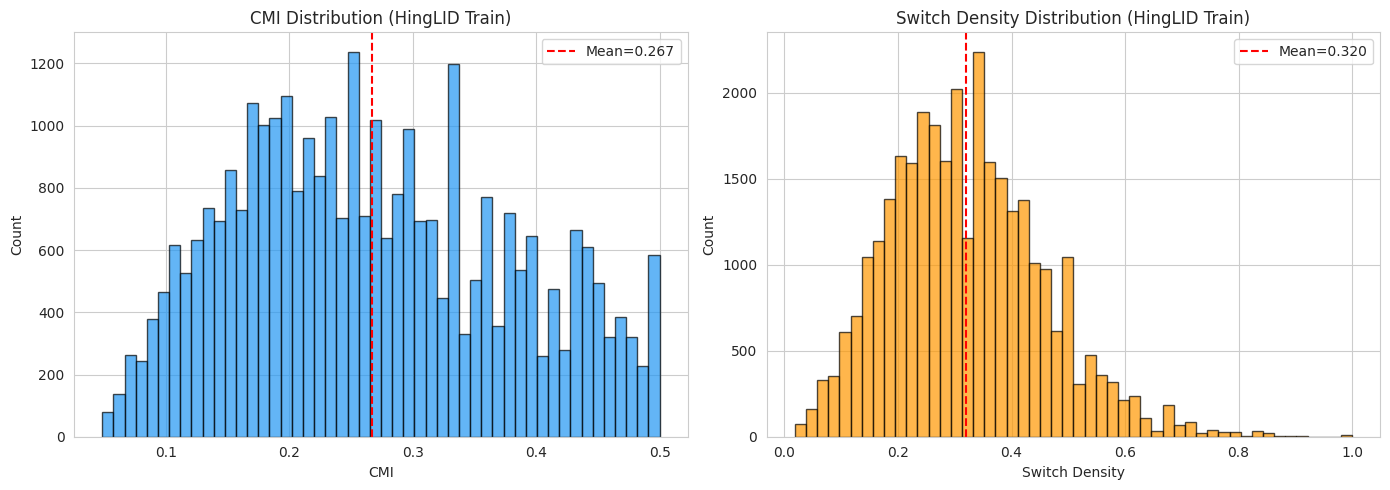

Figure saved: figures/hinglid_cmi_switch_dist.png


In [11]:
if IS_WORD_LEVEL_LID:
    print("=" * 70)
    print("════ REPORT BACK: CMI DISTRIBUTION ON HingLID ════")
    print("=" * 70)

    cmi_values = []
    sd_values = []
    for sample in lid_data["train"]:
        tags = [normalize_tag(t) for t in sample["tags"]]
        cmi_values.append(compute_cmi(tags))
        sd_values.append(compute_switch_density(tags))

    cmi_arr = np.array(cmi_values)
    sd_arr = np.array(sd_values)

    print(f"\nCMI statistics (train, {len(cmi_values)} sentences):")
    print(f"  Mean:   {cmi_arr.mean():.4f}")
    print(f"  Std:    {cmi_arr.std():.4f}")
    print(f"  Median: {np.median(cmi_arr):.4f}")
    print(f"  Min:    {cmi_arr.min():.4f}")
    print(f"  Max:    {cmi_arr.max():.4f}")
    for pct in [10, 25, 50, 75, 90]:
        print(f"  P{pct:2d}:    {np.percentile(cmi_arr, pct):.4f}")

    # CMI bin distribution
    bins = Counter(assign_cmi_bin(c) for c in cmi_values)
    print(f"\nCMI bin distribution:")
    for b in ["mono", "low", "mid-low", "mid-high", "high"]:
        count = bins.get(b, 0)
        print(f"  {b:10s}: {count:6d} ({count/len(cmi_values)*100:.1f}%)")

    print(f"\nSwitch density statistics:")
    print(f"  Mean:   {sd_arr.mean():.4f}")
    print(f"  Std:    {sd_arr.std():.4f}")
    print(f"  Median: {np.median(sd_arr):.4f}")

    # Plot CMI histogram
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(cmi_arr, bins=50, edgecolor="black", alpha=0.7, color="#2196F3")
    axes[0].set_xlabel("CMI")
    axes[0].set_ylabel("Count")
    axes[0].set_title("CMI Distribution (HingLID Train)")
    axes[0].axvline(cmi_arr.mean(), color="red", linestyle="--", label=f"Mean={cmi_arr.mean():.3f}")
    axes[0].legend()

    axes[1].hist(sd_arr, bins=50, edgecolor="black", alpha=0.7, color="#FF9800")
    axes[1].set_xlabel("Switch Density")
    axes[1].set_ylabel("Count")
    axes[1].set_title("Switch Density Distribution (HingLID Train)")
    axes[1].axvline(sd_arr.mean(), color="red", linestyle="--", label=f"Mean={sd_arr.mean():.3f}")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(FIG_DIR / "hinglid_cmi_switch_dist.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figure saved: {FIG_DIR / 'hinglid_cmi_switch_dist.png'}")

else:
    print("Skipping CMI computation on HingLID (sentence-level format).")

Download & Load Evaluation Datasets

In [12]:
print("=" * 70)
print("════ REPORT BACK: EVALUATION DATASETS ════")
print("=" * 70)

# ── Strategy: Try HuggingFace datasets first, then GitHub ──

from datasets import load_dataset

eval_datasets = {}

════ REPORT BACK: EVALUATION DATASETS ════


SemEval-2020 Task 9 — Sentiment Analysis (SentiMix Hi-En)

In [14]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Dataset 1: SemEval-2020 Task 9 — Sentiment Analysis (SentiMix Hi-En)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

print("\n─── SemEval-2020 Task 9 (SentiMix Hi-En) ───")

# Try loading via LinCE benchmark
semeval_loaded = False
try:
    # Attempt 1: LinCE benchmark on HuggingFace
    semeval_sa = load_dataset("lince", "sa_hineng", trust_remote_code=True)
    eval_datasets["semeval_sa"] = semeval_sa
    semeval_loaded = True
    print(f"✓ Loaded from 'lince/sa_hineng'")
    print(f"  Splits: {list(semeval_sa.keys())}")
    for split_name, split_data in semeval_sa.items():
        print(f"  {split_name}: {len(split_data)} samples")
    print(f"  Columns: {semeval_sa[list(semeval_sa.keys())[0]].column_names}")
    print(f"  Sample: {semeval_sa[list(semeval_sa.keys())[0]][0]}")
except Exception as e1:
    print(f"  LinCE load failed: {e1}")
    try:
        # Attempt 2: Direct dataset name
        semeval_sa = load_dataset("strombergnlp/sentimix", "hinglish", trust_remote_code=True)
        eval_datasets["semeval_sa"] = semeval_sa
        semeval_loaded = True
        print(f"✓ Loaded from 'strombergnlp/sentimix'")
    except Exception as e2:
        print(f"  Direct load failed: {e2}")
        try:
            # Attempt 3: search common variants
            for ds_name in [
                "Kamate/SemEval_2020_Task_9",
                "sem_eval_2020_task_9",
                "sentimix"
            ]:
                try:
                    semeval_sa = load_dataset(ds_name, trust_remote_code=True)
                    eval_datasets["semeval_sa"] = semeval_sa
                    semeval_loaded = True
                    print(f"✓ Loaded from '{ds_name}'")
                    break
                except Exception:
                    continue
        except Exception:
            pass

if not semeval_loaded:
    print("⚠️  Could not auto-load SemEval-2020 Task 9 data.")
    print("   Manual download required from: https://github.com/microsoft/GLUECoS")
    print("   Or from CodaLab: search 'SemEval 2020 Task 9 SentiMix'")


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'lince' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'lince' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



─── SemEval-2020 Task 9 (SentiMix Hi-En) ───


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'strombergnlp/sentimix' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'strombergnlp/sentimix' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  LinCE load failed: Dataset scripts are no longer supported, but found lince.py


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Kamate/SemEval_2020_Task_9' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Kamate/SemEval_2020_Task_9' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  Direct load failed: Dataset 'strombergnlp/sentimix' doesn't exist on the Hub or cannot be accessed.


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'sem_eval_2020_task_9' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'sem_eval_2020_task_9' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'sentimix' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not sup

⚠️  Could not auto-load SemEval-2020 Task 9 data.
   Manual download required from: https://github.com/microsoft/GLUECoS
   Or from CodaLab: search 'SemEval 2020 Task 9 SentiMix'


SemEval-2020 Task 9 — Sentiment Analysis (SentiMix Hi-En)

In [16]:

import os
import subprocess
from pathlib import Path

repo_dir = Path("/content/SemEval2020-Task9")

if not repo_dir.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/singhnivedita/SemEval2020-Task9.git",
            str(repo_dir)
        ],
        check=True
    )

# Find candidate dataset files
extensions = {".csv", ".tsv", ".txt", ".json", ".parquet"}
data_files = [
    p for p in repo_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print(f"Found {len(data_files)} candidate files:")
for p in data_files:
    print(p.relative_to(repo_dir))


Found 13 candidate files:
Fully Processed Datasets/ValidationOnly.tsv
Fully Processed Datasets/FinalTest.tsv
Fully Processed Datasets/Ty.txt
Fully Processed Datasets/FinalTrainingOnly.tsv
Pre Processing Code/Pre Processing V1/ValidationV1.tsv
Pre Processing Code/Pre Processing V1/TrainV1.tsv
Pre Processing Code/Pre Processing V2/ValidationV2.tsv
Pre Processing Code/Pre Processing V2/TrainV2.tsv
Pre Processing Code/Pre Processing For Test Data/Test.tsv
Pre Processing Code/Original Dataset/Test.txt
Pre Processing Code/Original Dataset/Validation.txt
Pre Processing Code/Original Dataset/Train.txt
Pre Processing Code/hindistopwords/hin.txt


SemEval-2020 Task 9 — Sentiment Analysis (SentiMix Hi-En)

In [24]:
import pandas as pd
from datasets import Dataset

train_df = pd.read_csv(
    "/content/SemEval2020-Task9/Fully Processed Datasets/FinalTrainingOnly.tsv",
    sep="\t",
    header=None,
    names=["id", "text", "label"]
)

# Check data
print(train_df.shape)
print(train_df.head())
print(train_df["label"].value_counts(dropna=False))

train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

# Store as a DatasetDict so your existing loop can work
eval_datasets["semeval_sa"] = {"train": train_dataset}

(14594, 3)
   id                                               text  label
0   3  pakistan ka ghra tauq pakistan israel ko tasle...      0
1  41  madarchod mull ye mathura nahi dikha tha jab m...      0
2  48  manya pradhan mantri mahoday shriman narendra ...      2
3  64            krishna jcb full trend chal rahi aa nan      2
4  66  loksabha janta sirf modi ko vote de rahi thi n...      2
label
1    5473
2    4869
0    4252
Name: count, dtype: int64


In [20]:
print("\n─── LinCE LID Hi-En (word-level gold tags) ───")

lince_lid_loaded = False
try:
    lince_lid = load_dataset("lince", "lid_hineng", trust_remote_code=True)
    eval_datasets["lince_lid"] = lince_lid
    lince_lid_loaded = True
    print(f"✓ Loaded from 'lince/lid_hineng'")
    print(f"  Splits: {list(lince_lid.keys())}")
    for split_name, split_data in lince_lid.items():
        print(f"  {split_name}: {len(split_data)} samples")
    print(f"  Columns: {lince_lid[list(lince_lid.keys())[0]].column_names}")
    print(f"  Sample: {lince_lid[list(lince_lid.keys())[0]][0]}")
except Exception as e:
    print(f"  LinCE LID load failed: {e}")
    print("  Will rely on L3Cube-HingLID for word-level LID validation.")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'lince' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'lince' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



─── LinCE LID Hi-En (word-level gold tags) ───
  LinCE LID load failed: Dataset scripts are no longer supported, but found lince.py
  Will rely on L3Cube-HingLID for word-level LID validation.


GLUECoS Sentiment (Hi-En)

In [21]:
print("\n─── GLUECoS Sentiment (Hi-En) ───")

gluecos_loaded = False
for ds_name in [
    "microsoft/GLUECoS",
    "SetFit/SentEval-CR",
    "sail/sailmdb",
]:
    try:
        gluecos_sa = load_dataset(ds_name, trust_remote_code=True)
        eval_datasets["gluecos_sa"] = gluecos_sa
        gluecos_loaded = True
        print(f"✓ Loaded from '{ds_name}'")
        break
    except Exception:
        continue

if not gluecos_loaded:
    # Try loading the Sub-Word SAIL dataset as an alternative
    try:
        # SAIL 2017 Hindi sentiment as alternative
        for ds_name in [
            "midas/hindi_sentiment",
            "Abhishek4896/hindi-english-code-mixed-tweets-sentiment",
        ]:
            try:
                alt_sa = load_dataset(ds_name, trust_remote_code=True)
                eval_datasets["alt_sentiment"] = alt_sa
                gluecos_loaded = True
                print(f"✓ Loaded alternative dataset from '{ds_name}'")
                print(f"  Splits: {list(alt_sa.keys())}")
                for split_name, split_data in alt_sa.items():
                    print(f"  {split_name}: {len(split_data)} samples")
                print(f"  Columns: {alt_sa[list(alt_sa.keys())[0]].column_names}")
                break
            except Exception:
                continue
    except Exception:
        pass

if not gluecos_loaded:
    print("⚠️  GLUECoS not on HuggingFace. Download from:")
    print("   https://github.com/microsoft/GLUECoS")
    print("   Follow their acquisition scripts for Sentiment (en_hi)")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'microsoft/GLUECoS' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'microsoft/GLUECoS' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



─── GLUECoS Sentiment (Hi-En) ───


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'SetFit/SentEval-CR' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'SetFit/SentEval-CR' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/447 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl:   0%|          | 0.00/427k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/109k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3012 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/753 [00:00<?, ? examples/s]

✓ Loaded from 'SetFit/SentEval-CR'


 L3Cube HingCorpus subset (transfer set — sample only)

In [22]:
print("\n─── L3Cube HingCorpus (transfer set sample) ───")
print("The full HingCorpus (52.93M sentences) is too large for Phase 1.")
print("Download link: https://drive.google.com/file/d/1s_6eHO9zDhxQ-xVN1TyNguszV1meZkl9/view")
print("We'll use a subset in Phase 3 for the transfer set.")

# ── Summary of loaded datasets ──
print("\n" + "=" * 70)
print("════ DATASET LOADING SUMMARY ════")
print("=" * 70)
for name, ds in eval_datasets.items():
    print(f"\n{name}:")
    if hasattr(ds, 'keys'):
        for split_name in ds.keys():
            print(f"  {split_name}: {len(ds[split_name])} samples")
    else:
        print(f"  {len(ds)} samples")

if not eval_datasets:
    print("\n⚠️  No datasets loaded automatically. Please report the errors above.")
    print("   I'll provide manual download instructions based on what failed.")


─── L3Cube HingCorpus (transfer set sample) ───
The full HingCorpus (52.93M sentences) is too large for Phase 1.
Download link: https://drive.google.com/file/d/1s_6eHO9zDhxQ-xVN1TyNguszV1meZkl9/view
We'll use a subset in Phase 3 for the transfer set.

════ DATASET LOADING SUMMARY ════

semeval_sa_train:
  14593 samples

gluecos_sa:
  train: 3012 samples
  test: 753 samples


Compute CMI & Switch Stats on Eval Data

In [26]:
def lid_predict_sentence(text: str) -> List[str]:
    """Apply LID tagger to a sentence, return per-word tags."""
    tokens = text.strip().split()
    if IS_WORD_LEVEL_LID:
        preds = lid_classifier.predict([t.lower() for t in tokens])
        if isinstance(preds, np.ndarray):
            preds = preds.tolist()
        return list(preds)
    else:
        return lid_classifier.predict([t.lower() for t in tokens])


def compute_dataset_cmi_stats(texts: List[str], desc: str = ""):
    """Compute CMI and switch density for a list of texts."""
    cmi_vals = []
    sd_vals = []
    for text in tqdm(texts, desc=f"Computing CMI [{desc}]"):
        tags = lid_predict_sentence(text)
        cmi_vals.append(compute_cmi(tags))
        sd_vals.append(compute_switch_density(tags))

    cmi_arr = np.array(cmi_vals)
    sd_arr = np.array(sd_vals)

    print(f"\n  CMI stats ({desc}, n={len(cmi_vals)}):")
    print(f"    Mean={cmi_arr.mean():.4f}, Std={cmi_arr.std():.4f}, "
          f"Median={np.median(cmi_arr):.4f}")

    bins = Counter(assign_cmi_bin(c) for c in cmi_vals)
    for b in ["mono", "low", "mid-low", "mid-high", "high"]:
        count = bins.get(b, 0)
        print(f"    {b:10s}: {count:5d} ({count/len(cmi_vals)*100:.1f}%)")

    print(f"  Switch density: Mean={sd_arr.mean():.4f}, Std={sd_arr.std():.4f}")

    return cmi_vals, sd_vals


# print("=" * 70)
# print("════ REPORT BACK: CMI STATS ON EVAL DATA ════")
# print("=" * 70)

# all_cmi_data = {}

# # Process each loaded dataset
# for ds_name, ds in eval_datasets.items():
#     print(f"\n{'─' * 50}")
#     print(f"Dataset: {ds_name}")
#     print(f"{'─' * 50}")

#     # Extract texts from the dataset
#     texts = []
#     for split_name in ds.keys():
#         split_data = ds[split_name]
#         # Try common text column names
#         text_col = None
#         for col in ["text", "sentence", "tokens", "words", "tweet", "utterance"]:
#             if col in split_data.column_names:
#                 text_col = col
#                 break

#         if text_col is None:
#             print(f"  ⚠️  No text column found in {split_name}. Columns: {split_data.column_names}")
#             # If tokens is a list column, join them
#             if "tokens" in split_data.column_names or "words" in split_data.column_names:
#                 col = "tokens" if "tokens" in split_data.column_names else "words"
#                 for sample in split_data:
#                     if isinstance(sample[col], list):
#                         texts.append(" ".join(sample[col]))
#                     else:
#                         texts.append(str(sample[col]))
#                 text_col = col
#             else:
#                 # Use first string column
#                 for col in split_data.column_names:
#                     sample_val = split_data[0][col]
#                     if isinstance(sample_val, str) and len(sample_val) > 10:
#                         text_col = col
#                         break
#                 if text_col:
#                     texts.extend(split_data[text_col])
#                 continue
#         else:
#             for sample in split_data:
#                 if isinstance(sample[text_col], list):
#                     texts.append(" ".join(sample[text_col]))
#                 else:
#                     texts.append(str(sample[text_col]))

#     if texts:
#         # Cap at 5000 for speed in Phase 1
#         max_n = min(5000, len(texts))
#         cmi_vals, sd_vals = compute_dataset_cmi_stats(
#             texts[:max_n], desc=f"{ds_name} (first {max_n})"
#         )
#         all_cmi_data[ds_name] = {"cmi": cmi_vals, "sd": sd_vals}
#     else:
#         print(f"  No texts extracted from {ds_name}")
from datasets import Dataset, DatasetDict
from tqdm.auto import tqdm
import numpy as np
from collections import Counter

all_cmi_data = {}

print("=" * 70)
print("CMI STATS ON EVALUATION DATA")
print("=" * 70)

for ds_name, ds in eval_datasets.items():
    print(f"\n{'─' * 50}")
    print(f"Dataset: {ds_name}")
    print(f"{'─' * 50}")

    # Handle either a Dataset or a DatasetDict
    if isinstance(ds, Dataset):
        splits = {"data": ds}
    elif isinstance(ds, DatasetDict):
        splits = ds
    elif isinstance(ds, dict):
        splits = ds
    else:
        print(f"Unsupported dataset type: {type(ds)}")
        continue

    for split_name, split_data in splits.items():
        columns = split_data.column_names
        print(f"\nSplit: {split_name}")
        print(f"Columns: {columns}")

        # Prefer the actual text column
        text_col = next(
            (c for c in ["text", "sentence", "tweet",
                         "utterance", "tokens", "words"]
             if c in columns),
            None
        )

        if text_col is None:
            print("No text column found; skipping.")
            continue

        texts = []
        for value in split_data[text_col]:
            if isinstance(value, list):
                value = " ".join(map(str, value))
            if isinstance(value, str) and value.strip():
                texts.append(value.strip())

        if not texts:
            print("No usable texts found.")
            continue

        max_n = min(5000, len(texts))

        cmi_vals, sd_vals = compute_dataset_cmi_stats(
            texts[:max_n],
            desc=f"{ds_name}/{split_name} (n={max_n})"
        )

        all_cmi_data[f"{ds_name}_{split_name}"] = {
            "cmi": cmi_vals,
            "sd": sd_vals
        }

CMI STATS ON EVALUATION DATA

──────────────────────────────────────────────────
Dataset: semeval_sa_train
──────────────────────────────────────────────────

Split: data
Columns: ['3', 'pakistan ka ghra tauq pakistan israel ko tasleem nahein kerta isko palestin kehta - occupi palestin nan', '0']
No text column found; skipping.

──────────────────────────────────────────────────
Dataset: gluecos_sa
──────────────────────────────────────────────────

Split: train
Columns: ['text', 'label', 'label_text']


Computing CMI [gluecos_sa/train (n=3012)]:   0%|          | 0/3012 [00:00<?, ?it/s]


  CMI stats (gluecos_sa/train (n=3012), n=3012):
    Mean=0.0385, Std=0.0529, Median=0.0000
    mono      :  1562 (51.9%)
    low       :  1068 (35.5%)
    mid-low   :   373 (12.4%)
    mid-high  :     8 (0.3%)
    high      :     1 (0.0%)
  Switch density: Mean=0.0730, Std=0.0969

Split: test
Columns: ['text', 'label', 'label_text']


Computing CMI [gluecos_sa/test (n=753)]:   0%|          | 0/753 [00:00<?, ?it/s]


  CMI stats (gluecos_sa/test (n=753), n=753):
    Mean=0.0386, Std=0.0490, Median=0.0000
    mono      :   377 (50.1%)
    low       :   283 (37.6%)
    mid-low   :    93 (12.4%)
    mid-high  :     0 (0.0%)
    high      :     0 (0.0%)
  Switch density: Mean=0.0735, Std=0.0915

──────────────────────────────────────────────────
Dataset: semeval_sa
──────────────────────────────────────────────────

Split: train
Columns: ['id', 'text', 'label']


Computing CMI [semeval_sa/train (n=5000)]:   0%|          | 0/5000 [00:00<?, ?it/s]


  CMI stats (semeval_sa/train (n=5000), n=5000):
    Mean=0.2452, Std=0.1349, Median=0.2390
    mono      :   286 (5.7%)
    low       :   446 (8.9%)
    mid-low   :  2436 (48.7%)
    mid-high  :  1643 (32.9%)
    high      :   189 (3.8%)
  Switch density: Mean=0.3049, Std=0.1706


Visualization Dashboard

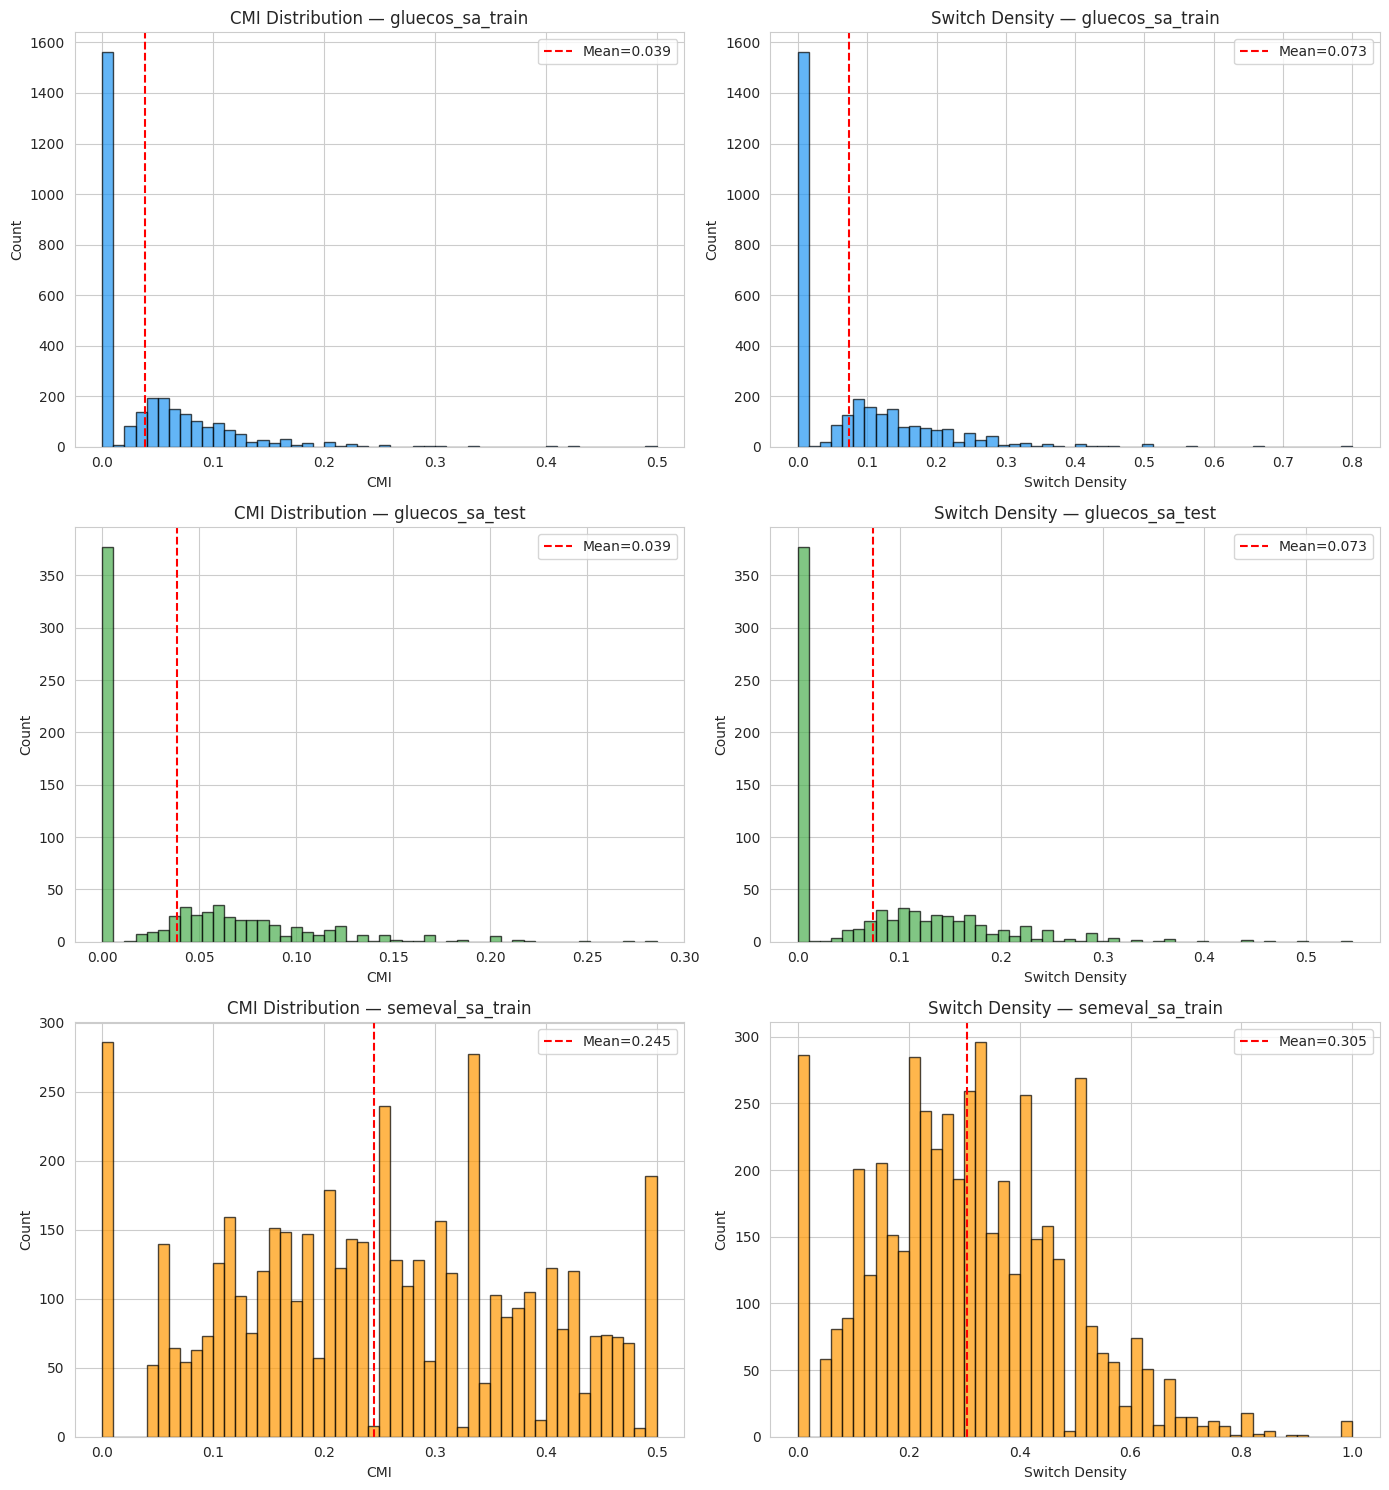


Figure saved: figures/eval_cmi_switch_dist.png


In [27]:
if all_cmi_data:
    n_datasets = len(all_cmi_data)
    fig, axes = plt.subplots(n_datasets, 2, figsize=(14, 5 * n_datasets))
    if n_datasets == 1:
        axes = axes.reshape(1, -1)

    colors = ["#2196F3", "#4CAF50", "#FF9800", "#E91E63", "#9C27B0"]

    for idx, (ds_name, data) in enumerate(all_cmi_data.items()):
        color = colors[idx % len(colors)]

        # CMI histogram
        cmi_arr = np.array(data["cmi"])
        axes[idx, 0].hist(cmi_arr, bins=50, edgecolor="black", alpha=0.7, color=color)
        axes[idx, 0].set_xlabel("CMI")
        axes[idx, 0].set_ylabel("Count")
        axes[idx, 0].set_title(f"CMI Distribution — {ds_name}")
        axes[idx, 0].axvline(cmi_arr.mean(), color="red", linestyle="--",
                             label=f"Mean={cmi_arr.mean():.3f}")
        axes[idx, 0].legend()

        # Switch density histogram
        sd_arr = np.array(data["sd"])
        axes[idx, 1].hist(sd_arr, bins=50, edgecolor="black", alpha=0.7, color=color)
        axes[idx, 1].set_xlabel("Switch Density")
        axes[idx, 1].set_ylabel("Count")
        axes[idx, 1].set_title(f"Switch Density — {ds_name}")
        axes[idx, 1].axvline(sd_arr.mean(), color="red", linestyle="--",
                             label=f"Mean={sd_arr.mean():.3f}")
        axes[idx, 1].legend()

    plt.tight_layout()
    plt.savefig(FIG_DIR / "eval_cmi_switch_dist.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nFigure saved: {FIG_DIR / 'eval_cmi_switch_dist.png'}")

SUMMARY

In [29]:
print("\n" + "=" * 70)
print("════ PHASE 1 SUMMARY ════")
print("=" * 70)

print("""

1. TEACHER INSPECTION
   - Hidden size, num layers, vocab size, total params
   - This confirms the compression target

2. LID DATA FORMAT
   - WORD-LEVEL or SENTENCE-LEVEL
   - Number of samples per split
   - Tag distribution

3. LID VALIDATION
   - Accuracy and per-class F1
   - This tells us how much noise feeds into CMI bins

4. CMI DISTRIBUTION ON HingLID
   - Mean, std, percentiles
   - Bin distribution (mono / low / mid-low / mid-high / high)

5. EVALUATION DATASETS
   - Which loaded successfully, which failed
   - Sizes and column names

6. CMI STATS ON EVAL DATA
   - Per-dataset CMI means and bin distributions
   - This is our first look at how mixed the eval data is


Phase 2: Teacher fine-tuning + CMI-stratified
evaluation. That gives us the first publishable result: "where does the
teacher struggle on code-mixed text?"
""")



════ PHASE 1 SUMMARY ════


1. TEACHER INSPECTION
   - Hidden size, num layers, vocab size, total params
   - This confirms the compression target

2. LID DATA FORMAT
   - WORD-LEVEL or SENTENCE-LEVEL
   - Number of samples per split
   - Tag distribution

3. LID VALIDATION
   - Accuracy and per-class F1
   - This tells us how much noise feeds into CMI bins

4. CMI DISTRIBUTION ON HingLID
   - Mean, std, percentiles
   - Bin distribution (mono / low / mid-low / mid-high / high)

5. EVALUATION DATASETS
   - Which loaded successfully, which failed
   - Sizes and column names

6. CMI STATS ON EVAL DATA
   - Per-dataset CMI means and bin distributions
   - This is our first look at how mixed the eval data is


Phase 2: Teacher fine-tuning + CMI-stratified
evaluation. That gives us the first publishable result: "where does the
teacher struggle on code-mixed text?"

